# Toxicity Prediction of Food Contaminants (ApisTox)

**Goal:** predict whether a pesticide is toxic to honey bees (*Apis mellifera*) from its SMILES string. Pesticide residues are a food-safety concern, so an early screening model can help prioritise compounds for testing.

**Note:** the target is honey-bee toxicity, not human toxicity.

**Results (scaffold split, test set):**

| Model | Test ROC-AUC (mean of 3 seeds) |
|---|---|
| Random Forest (ECFP) | 0.759 (0.751–0.768) |
| GNN (7 atom features) | 0.570 (0.488–0.641) |

**Notebook structure:**
1. Setup and data loading
2. SMILES validation
3. Scaffold split
4. Class balance (`pos_weight`)
5. Random Forest (main model)
6. Graph construction and GNN
7. GNN learning rate selection (validation only)
8. GNN final evaluation (3 seeds)
9. F1 score with a validation-selected threshold
10. Predicted-probability plot

**Rule:** the test set is used only for the final numbers in sections 5, 8 and 9–10. Decisions (learning rate, threshold) use validation only.

Install RDKit and PyTorch Geometric, then load the ApisTox CSV (1,035 pesticides, columns include `SMILES` and the binary `label`) from GitHub.

In [12]:
!pip install rdkit
!pip install torch_geometric

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 20.4 MB/s  0:00:00


In [2]:
import pandas as pd

RAW_URL = "https://raw.githubusercontent.com/naimxno/food-contaminant-toxicity/refs/heads/main/dataset_final.csv"
df = pd.read_csv(RAW_URL)

print(df.shape)
print(df.columns.tolist())
print(df["label"].value_counts())

(1035, 13)
['name', 'CID', 'CAS', 'SMILES', 'source', 'year', 'toxicity_type', 'herbicide', 'fungicide', 'insecticide', 'other_agrochemical', 'label', 'ppdb_level']
label
0    739
1    296
Name: count, dtype: int64


## 2. SMILES validation

Remove any SMILES that RDKit cannot parse. All 1,035 were valid, so nothing was removed.

In [5]:
from rdkit import Chem

valid = df["SMILES"].apply(lambda s: isinstance(s, str) and Chem.MolFromSmiles(s) is not None)

print("RDKit could not read it :", (~valid).sum())
df_clean = df[valid].reset_index(drop=True)
print("Clean Data:", len(df_clean))
print(df_clean["label"].value_counts())

RDKit could not read it : 0
Clean Data: 1035
label
0    739
1    296
Name: count, dtype: int64


## 3. Scaffold split

Compounds sharing a Murcko scaffold go to the same split, so the test set contains unseen chemistry. Split: train 828, validation 103, test 104. Toxic share is lower in validation (20%) and test (19%) than overall (29%), which is a property of the scaffold split and is discussed in the limitations.

In [8]:
from rdkit.Chem.Scaffolds import MurckoScaffold
from collections import defaultdict

df_clean["scaffold"] = df_clean["SMILES"].apply(
    lambda s: MurckoScaffold.MurckoScaffoldSmiles(smiles=s, includeChirality=False)
)
print("Unique scaffold:", df_clean["scaffold"].nunique(), "| Total Data:", len(df_clean))

def scaffold_split(scaffolds, frac=(0.8, 0.1, 0.1)):
    groups = defaultdict(list)
    for i, s in enumerate(scaffolds):
        groups[s].append(i)
    sets = sorted(groups.values(), key=len, reverse=True)
    n = len(scaffolds)
    train, val, test = [], [], []
    for g in sets:
        if len(train) + len(g) <= frac[0] * n:
            train += g
        elif len(val) + len(g) <= frac[1] * n:
            val += g
        else:
            test += g
    return train, val, test

idx_train, idx_val, idx_test = scaffold_split(df_clean["scaffold"].tolist())

print("Train:", len(idx_train), "| Val:", len(idx_val), "| Test:", len(idx_test))

for name, idx in [("Train", idx_train), ("Val", idx_val), ("Test", idx_test)]:
    print(name, "toxic ratio:", round(df_clean.iloc[idx]["label"].mean(), 3))

Unique scaffold: 424 | Total Data: 1035
Train: 828 | Val: 103 | Test: 104
Train toxic ratio: 0.308
Val toxic ratio: 0.204
Test toxic ratio: 0.192


## 4. Class balance

`pos_weight` = negatives ÷ positives in the training set (≈ 2.25). It is used by the GNN's loss so that toxic compounds are not ignored. The Random Forest uses `class_weight="balanced"` instead.

In [9]:
import torch

n_pos = df_clean.iloc[idx_train]["label"].sum()
n_neg = len(idx_train) - n_pos
pos_weight = torch.tensor([n_neg / n_pos], dtype=torch.float)
print("pos_weight:", pos_weight.item())

pos_weight: 2.247058868408203


## 5. Random Forest (main model)

Morgan fingerprints (radius 2, 2048 bits), one Random Forest per seed, evaluated on the test set.

Result: mean test ROC-AUC 0.759, range 0.751–0.768. The test set has 20 toxic compounds out of 104.

In [10]:
from rdkit.Chem import rdFingerprintGenerator
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
import numpy as np

gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
fps = np.array([gen.GetFingerprintAsNumPy(Chem.MolFromSmiles(s)) for s in df_clean["SMILES"]])
y = df_clean["label"].values

def run_rf(seed):
    rf = RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                random_state=seed, n_jobs=-1)
    rf.fit(fps[idx_train], y[idx_train])
    return roc_auc_score(y[idx_test], rf.predict_proba(fps[idx_test])[:, 1])

aucs = [run_rf(s) for s in [0, 1, 2]]
print("RF test AUC per seed:", [round(a, 4) for a in aucs])
print("Avg:", round(np.mean(aucs), 4), "| std:", round(np.std(aucs), 4))
print("Test-এ toxic number :", int(y[idx_test].sum()), "| total:", len(idx_test))

RF test AUC per seed: [np.float64(0.7577), np.float64(0.7679), np.float64(0.7512)]
গড়: 0.7589 | std: 0.0069
Test-এ toxic সংখ্যা: 20 | মোট: 104


## 6. Graph construction and GNN model

Each compound is a graph: atoms are nodes (7 features), bonds are edges. The GNN has two `GCNConv` layers, `global_add_pool`, and one output logit.

In [13]:
import torch
import torch.nn as nn
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader

def atom_features(atom):
    return [
        atom.GetAtomicNum(),
        atom.GetTotalNumHs(),
        atom.GetDegree(),
        int(atom.GetIsAromatic()),
        int(atom.IsInRing()),
        atom.GetFormalCharge(),
        int(atom.GetHybridization()),
    ]

def make_graph(smiles, label):
    mol = Chem.MolFromSmiles(smiles)
    x = torch.tensor([atom_features(a) for a in mol.GetAtoms()], dtype=torch.float)
    edges = []
    for b in mol.GetBonds():
        i, j = b.GetBeginAtomIdx(), b.GetEndAtomIdx()
        edges += [[i, j], [j, i]]
    edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()
    return Data(x=x, edge_index=edge_index, y=torch.tensor([[float(label)]]))

graphs = [make_graph(s, l) for s, l in zip(df_clean["SMILES"], df_clean["label"])]

train_loader = DataLoader([graphs[i] for i in idx_train], batch_size=32, shuffle=True)
val_loader = DataLoader([graphs[i] for i in idx_val], batch_size=32, shuffle=False)
test_loader = DataLoader([graphs[i] for i in idx_test], batch_size=32, shuffle=False)
print("graphs:", len(graphs))

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


graphs: 1035


In [14]:
from torch_geometric.nn import GCNConv, global_add_pool
from sklearn.metrics import roc_auc_score

class BinaryGNN(nn.Module):
    def __init__(self, in_dim=7, hid=64):
        super().__init__()
        self.conv1 = GCNConv(in_dim, hid)
        self.conv2 = GCNConv(hid, hid)
        self.lin = nn.Linear(hid, 1)

    def forward(self, x, edge_index, batch):
        x = self.conv1(x, edge_index).relu()
        x = self.conv2(x, edge_index).relu()
        x = global_add_pool(x, batch)
        return self.lin(x)

def predict_proba(model, loader):
    model.eval()
    P, Y = [], []
    with torch.no_grad():
        for b in loader:
            P.append(torch.sigmoid(model(b.x, b.edge_index, b.batch)).squeeze(1))
            Y.append(b.y.squeeze(1))
    return torch.cat(P).numpy(), torch.cat(Y).numpy()

def train_binary(lr=0.003, max_epochs=300, patience=20, seed=0):
    torch.manual_seed(seed)
    model = BinaryGNN()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    best_auc, best_state, best_epoch, wait = -1, None, 0, 0

    for epoch in range(max_epochs):
        model.train()
        for b in train_loader:
            logits = model(b.x, b.edge_index, b.batch)
            loss = loss_fn(logits, b.y)
            opt.zero_grad()
            loss.backward()
            opt.step()

        p, yv = predict_proba(model, val_loader)
        val_auc = roc_auc_score(yv, p)
        if val_auc > best_auc:
            best_auc, best_epoch = val_auc, epoch
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
            wait = 0
        else:
            wait += 1
        if wait >= patience:
            break

    model.load_state_dict(best_state)
    return best_auc, best_epoch, model

In [15]:
gnn_aucs = []
for s in [0, 1, 2]:
    _, ep, model_s = train_binary(seed=s)
    p, yt = predict_proba(model_s, test_loader)
    auc = roc_auc_score(yt, p)
    gnn_aucs.append(auc)
    print(f"GNN seed {s} | best epoch {ep} | test AUC {auc:.4f}")

print("GNN Avg:", round(np.mean(gnn_aucs), 4), "| std:", round(np.std(gnn_aucs), 4))

GNN seed 0 | best epoch 75 | test AUC 0.5810
GNN seed 1 | best epoch 21 | test AUC 0.6405
GNN seed 2 | best epoch 45 | test AUC 0.4881
GNN Avg: 0.5698 | std: 0.0627


## 7. GNN learning rate selection (validation only)

Three learning rates × three seeds, chosen by mean validation ROC-AUC. Result: `lr = 0.003` (validation AUC 0.613). Learning rates 0.01 and 0.001 were lower. All validation AUCs stayed between 0.54 and 0.61, far below the Random Forest.

In [17]:
results_b = {}
for lr in [0.01, 0.003, 0.001]:
    vals = []
    for s in [0, 1, 2]:
        v, _, _ = train_binary(lr=lr, seed=s)
        vals.append(v)
    results_b[lr] = np.mean(vals)
    print(f"lr = {lr} | Avg val AUC = {np.mean(vals):.4f} | Val = {[round(v, 4) for v in vals]}")

print("Best lr:", max(results_b, key=results_b.get))

lr = 0.01 | Avg val AUC = 0.5966 | Val = [np.float64(0.5999), np.float64(0.5552), np.float64(0.6347)]
lr = 0.003 | Avg val AUC = 0.6127 | Val = [np.float64(0.6452), np.float64(0.5947), np.float64(0.5981)]
lr = 0.001 | Avg val AUC = 0.5399 | Val = [np.float64(0.5372), np.float64(0.5534), np.float64(0.529)]
Best lr: 0.003


## 8. GNN final evaluation (test, 3 seeds)

Each seed trains with early stopping on validation AUC, then is evaluated once on the test set.

Result: mean test ROC-AUC 0.570 (0.581, 0.641, 0.488). The GNN is clearly weaker than the Random Forest on this small dataset.

*Note:* this section ran before the learning-rate selection in section 7 and used the default `lr=0.003`. Section 7 confirmed that value, so the numbers stand.

In [18]:
gnn_aucs = []
for s in [0, 1, 2]:
    _, ep, model_s = train_binary(seed=s)
    p, yt = predict_proba(model_s, test_loader)
    auc = roc_auc_score(yt, p)
    gnn_aucs.append(auc)
    print(f"GNN seed {s} | best epoch {ep} | test AUC {auc:.4f}")

print("GNN Avg:", round(np.mean(gnn_aucs), 4), "| std:", round(np.std(gnn_aucs), 4))

GNN seed 0 | best epoch 75 | test AUC 0.5810
GNN seed 1 | best epoch 21 | test AUC 0.6405
GNN seed 2 | best epoch 45 | test AUC 0.4881
GNN Avg: 0.5698 | std: 0.0627


## 9. F1 score (threshold chosen on validation)

ROC-AUC ranks compounds but does not give a yes/no decision. F1 needs a threshold on the predicted probability. The threshold is chosen on the **validation** set (maximising F1), then applied once to the test set.

In [19]:
from sklearn.metrics import f1_score, precision_score, recall_score

# Random Forest trained on train only (seed 0), probabilities on validation and test
rf_eval = RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                 random_state=0, n_jobs=-1)
rf_eval.fit(fps[idx_train], y[idx_train])
p_val = rf_eval.predict_proba(fps[idx_val])[:, 1]
p_test = rf_eval.predict_proba(fps[idx_test])[:, 1]
y_val, y_test = y[idx_val], y[idx_test]

# Choose the threshold on validation only
thresholds = np.arange(0.05, 0.95, 0.01)
val_f1 = [f1_score(y_val, (p_val >= t).astype(int), zero_division=0) for t in thresholds]
best_t = float(thresholds[int(np.argmax(val_f1))])
print("Best threshold (validation):", round(best_t, 2), "| validation F1:", round(max(val_f1), 4))

# Apply once to test
pred_test = (p_test >= best_t).astype(int)
print("Test F1:", round(f1_score(y_test, pred_test), 4))
print("Test precision:", round(precision_score(y_test, pred_test, zero_division=0), 4))
print("Test recall:", round(recall_score(y_test, pred_test, zero_division=0), 4))
print("Test ROC-AUC:", round(roc_auc_score(y_test, p_test), 4))

Best threshold (validation): 0.29 | validation F1: 0.5357
Test F1: 0.4706
Test precision: 0.3871
Test recall: 0.6
Test ROC-AUC: 0.7577


## 10. Predicted-probability plot

Distribution of Random Forest test probabilities, split by the true label. If the model separates the classes, the toxic (1) distribution should sit higher than the non-toxic (0) one. The dashed line is the validation-selected threshold.

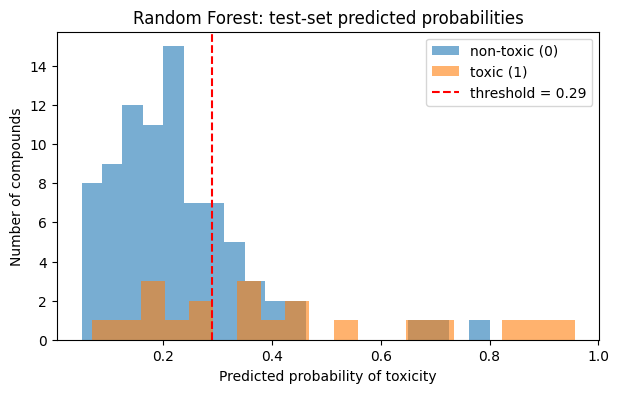

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.hist(p_test[y_test == 0], bins=20, alpha=0.6, label="non-toxic (0)")
plt.hist(p_test[y_test == 1], bins=20, alpha=0.6, label="toxic (1)")
plt.axvline(best_t, color="red", linestyle="--", label=f"threshold = {best_t:.2f}")
plt.xlabel("Predicted probability of toxicity")
plt.ylabel("Number of compounds")
plt.title("Random Forest: test-set predicted probabilities")
plt.legend()
plt.savefig("toxicity_probability_plot.png", dpi=150, bbox_inches="tight")
plt.show()

## Results and limitations

| Model | Test ROC-AUC (mean of 3 seeds) |
|---|---|
| Random Forest (ECFP) | 0.759 |
| GNN (7 features) | 0.570 |

F1 and the threshold are reported in section 9.

**Limitations:**
- Only 20 toxic compounds in the test set, so AUC and F1 are uncertain.
- Scaffold split leaves fewer toxic compounds in validation and test than overall.
- Target is honey-bee toxicity, not human toxicity.
- The GNN uses only 7 atom features and a small training set.

**Food-safety context:** pesticide residues in food are a monitoring concern. A screening model can rank compounds for experimental testing, but it does not replace toxicological assessment.